# ADP 24회 - 출제 주제 기반 복원 연습

출처: 기출문제 모음 PDF pp.3~4: 학생 결석 예측, 광고 회귀, 두 공정, Bayes, 평균 CI

**복원 연습 자료·예시 풀이이며 공식 정답이 아닙니다.** 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

동봉 data를 사용하며 원 질문·보완 조건·풀이를 분리합니다. 입력 파일은 UTF-8. 저장소 루트 또는 현재 회차 폴더에서 실행할 수 있습니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'24회';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 학생 결석 회귀

자료: student_absence.csv

395명·12특성 합성. count 타깃 absences. 7:3 분할, train CV RMSE로 모델 선택.

### 1-1

결측·분포·범주형 변수를 탐색하고 적합 전처리 근거를 제시하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** count 특성의 과산포·0 집중·타깃 범위를 점검합니다. 결측이 없는데 대치 성과가 생겼다고 주장하지 않습니다.

        sex         age  ...     leisure    absences
count   395  395.000000  ...  395.000000  395.000000
unique    2         NaN  ...         NaN         NaN
top       M         NaN  ...         NaN         NaN
freq    209         NaN  ...         NaN         NaN
mean    NaN   18.045570  ...    2.962025    7.078680
std     NaN    2.049625  ...    1.403793    3.649967
min     NaN   15.000000  ...    1.000000    0.000000
25%     NaN   16.000000  ...    2.000000    4.706206
50%     NaN   18.000000  ...    3.000000    7.141734
75%     NaN   20.000000  ...    4.000000    9.200618
max     NaN   21.000000  ...    5.000000   18.854264

[11 rows x 13 columns]
sex                  0
age                  0
parents_separated    0
mother_education     0
father_education     0
guardian             0
reason               0
travel_time          0
study_time           0
failure              0
family_relation      0
leisure              0
absences             0
dtype: int64


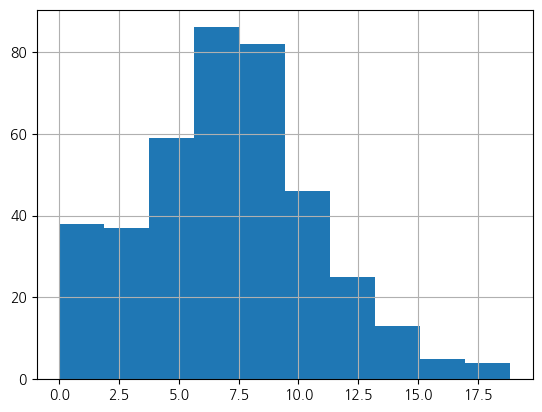

In [2]:
absent=load('student_absence.csv');print(absent.describe(include='all'));print(absent.isna().sum());absent.absences.hist();plt.show()

### 1-2

LinearRegression·RandomForest·SVR를 train CV RMSE로 비교해 선택하고 test RMSE·R²를 보고하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 선정 지표는 오차 크기에 민감한 RMSE, test는 선정 후 한 번만 평가합니다. count 예측에 음수가 나오는 모델은 Poisson 등과 비교해야 합니다.

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score
X=absent.drop(columns='absences');y=absent.absences;train,test=train_test_split(np.arange(len(y)),test_size=.3,random_state=1234)
rows=[];models={}
for name,est in [('linear',LinearRegression()),('rf',RandomForestRegressor(n_estimators=50,random_state=1234)),('svr',SVR())]:
    pipe=tabular_pipeline(X,est);scores=cross_val_score(pipe,X.iloc[train],y.iloc[train],cv=3,scoring='neg_mean_squared_error');rows.append({'model':name,'CV_RMSE':np.sqrt(-scores).mean()});models[name]=pipe
ranking=pd.DataFrame(rows);print(ranking);winner=ranking.loc[ranking.CV_RMSE.idxmin(),'model'];chosen=models[winner].fit(X.iloc[train],y.iloc[train]);pred=chosen.predict(X.iloc[test]);print(winner,{'RMSE':np.sqrt(mean_squared_error(y.iloc[test],pred)),'R2':r2_score(y.iloc[test],pred)})

    model   CV_RMSE
0  linear  3.095176
1      rf  3.086232
2     svr  3.142445
rf {'RMSE': np.float64(3.349281189490483), 'R2': 0.19597984219454467}


### 1-3

개선 방법 및 실제 시스템 적용의 제한을 설명하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 예측은 개입 효과의 인과 추정이 아닙니다. 학습 데이터에서의 상관으로 징계·지원 정책을 직접 결정하지 않습니다.

In [4]:
print('누락 패턴·학교 간 분포 차이·count 제약·학생 반복 그룹 분할 검토. Pipeline 버전 저장, 사용자별 접근제어, 재학습 전 보류 평가와 오류비용 검토.')

누락 패턴·학교 간 분포 차이·count 제약·학생 반복 그룹 분할 검토. Pipeline 버전 저장, 사용자별 접근제어, 재학습 전 보류 평가와 오류비용 검토.


## 2. 광고 다중회귀

자료: advertising.csv

광고비/R&D/sales 수치 10행. 설명 회귀, 표본이 매우 작아 추론 불안정.

### 2-1

광고비와 연구개발비로 sales를 설명하는 회귀식을 추정하고 전체 회귀 유의성을 검정하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** H0: 두 설명변수 계수가 모두 0입니다. 개별 t검정과 전체 F검정을 구분합니다.

In [5]:
ad=load('advertising.csv');ad_model=sm.OLS(ad.sales,sm.add_constant(ad[['advertising','rd']])).fit();print(ad_model.summary());print({'F':ad_model.fvalue,'F_p':ad_model.f_pvalue,'coefficients':ad_model.params.to_dict()})

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.994
Method:                 Least Squares   F-statistic:                     702.0
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           8.60e-09
Time:                        16:04:01   Log-Likelihood:                -15.126
No. Observations:                  10   AIC:                             36.25
Df Residuals:                       7   BIC:                             37.16
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           9.1145      1.366      6.671      

## 3. 알려진 분산 두 공정 평균

자료: 데이터 없음

자료가 원 시험 숫자와 다를 수 있다고 원문이 명시. n_A=n_B=30, 평균 5.7/5.6, 모표준편차 .03/.04, alpha=.05 양측으로 보완.

### 3-1

두 공정 평균이 같은지 알려진 모분산 Z검정을 수행하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** H0:mu_A=mu_B. 원 PDF 표본수·표준편차 표현이 불명확해 독립 표본수와 알려진 모표준편차를 보완했습니다. .03/.04가 표본 SD면 Welch가 필요합니다.

In [6]:
z=(5.7-5.6)/np.sqrt(.03**2/30+.04**2/30);p=2*stats.norm.sf(abs(z));print({'z':z,'p_value':p,'reject_H0':p<.05})

{'z': np.float64(10.954451150103381), 'p_value': np.float64(6.326068263673096e-28), 'reject_H0': np.True_}


## 4. 감염 Bayes

자료: 데이터 없음

예측+ 행: 실제+370, 실제-10; 예측- 행: 실제+15, 실제-690. 원문 표 보존.

### 4-1

양성 예측을 받은 사람이 실제 감염자일 확률을 Bayes 공식으로 계산하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 민감도 P(예측+|실제+)와 양성예측도 P(실제+|예측+)를 뒤바꾸지 않습니다. 유병률이 달라지면 PPV도 달라집니다.

In [7]:
TP,FP,FN,TN=370,10,15,690;prevalence=(TP+FN)/(TP+FP+FN+TN);sensitivity=TP/(TP+FN);fpr=FP/(FP+TN);ppv=sensitivity*prevalence/(sensitivity*prevalence+fpr*(1-prevalence));print({'P(infected|positive)':ppv,'direct':TP/(TP+FP)})

{'P(infected|positive)': 0.9736842105263157, 'direct': 0.9736842105263158}


## 5. 소표본 평균 신뢰구간

자료: sample.csv

9개 합성 관측. 정규 모형 가정, 95% 양측 CI. 모 SD 알려진 경우 .4.

### 5-1

모분산 미지/모 SD=.4일 때 각각 평균의 95% 신뢰구간을 계산하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 표본 SD를 모 SD처럼 취급하지 않습니다. 신뢰구간은 반복 표집에서의 포함률이며 고정 모수의 사후 확률이 아닙니다.

In [8]:
sample=load('sample.csv').value;n=len(sample);mean=sample.mean();t_ci=stats.t.interval(.95,n-1,loc=mean,scale=sample.std(ddof=1)/np.sqrt(n));z_ci=stats.norm.interval(.95,loc=mean,scale=.4/np.sqrt(n));print({'t_CI':t_ci,'known_sigma_Z_CI':z_ci})

{'t_CI': (np.float64(9.889491586241416), np.float64(10.310508413758587)), 'known_sigma_Z_CI': (np.float64(9.838671468727995), np.float64(10.361328531272008))}
